# Trend, seasonality and baselines on Flipkart's weeks: where is the peak, and what do three rules say for one week?

**Week 4, Friday, chapter 5, the case's first chapter.** It applies two of the day's
topics: trend and seasonality, read before modelling (concept notebook 01), and naive,
seasonal naive and drift baselines (concept notebook 02). On the chai stall (invented)
those notebooks found a weekly beat of 7 days, growth of 10 percent a year read a season
apart, and a seasonal naive that missed next Sunday by 1 cup where naive missed by 43.

**The ticket.** Flipkart, the Lucknow fulfilment centre (FC), the warehouse where orders are packed
and shipped. The centre has 104 weeks of outbound shipments, the weeks beginning Monday 30 September
2024 to Monday 21 September 2026. Diwali fell on Thursday 31 October 2024 and Monday 20 October 2025,
and falls on Sunday 8 November 2026; the festive sale runs in the third and second weeks before
Diwali's week. A packer packs about 120 shipments a shift, and a packer-shift is one packer working
one shift. The planner must book packer shifts for the eight weeks beginning 12 October to 30
November 2026, the festive window. A vendor's demand model promises the window 22 percent above the
same weeks last year; finance's rule is those weeks plus 4 percent: eighteen percentage points apart.
A late shipment costs Rs 25 (assumed, Rs 15 to 40). A spare shipment, planned for and never shipped,
leaves part of a packer-shift idle: Rs 650 a shift (assumed, Rs 500 to 800) over 120 shipments, Rs
5.42 a shipment. Illustrative case: the company is real, the situation and the data are synthetic, built for this class.

**Who needs the answer.** The FC planner, who books packer shifts weeks before the festival
and cannot add a shift on the day, and the regional operations head, who signs the plan. A
rule that puts the busiest week in the wrong place books packers for a week that is quiet.

**The questions on the way.** Where is each year's peak on twelve real weeks? What do three
rules say for Diwali 2025's own week? Which week does a copy of last year put the peak in?
How far does Diwali's week move into 2026? Does the full series show the same shape?

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

rows = pd.read_csv("../data/C2_W04_D05_twelve_rows_STUDENT.csv", parse_dates=["week_start"])
s = rows.set_index("week_start").shipments          # shipments, looked up by the week's Monday
rows

,week_start,shipments
0,2024-10-07,312900
1,2024-10-14,401000
2,2024-10-21,356200
3,2024-10-28,296900
4,2024-11-04,180600
5,2024-11-11,212700
6,2025-09-29,331200
7,2025-10-06,418200
8,2025-10-13,369000
9,2025-10-20,308900


## Where is each year's busiest week on the twelve rows?

The twelve rows are six weeks around Diwali 2024 and six around Diwali 2025, straight from
the centre's data. Notebook 01 read a series' shape before any rule; this is the same
reading on Flipkart's weeks.

**Predict before you run.** In each year, which week ships the most?

a) Diwali's own week
b) the week before Diwali's week
c) two weeks before Diwali's week
d) the week after Diwali's week

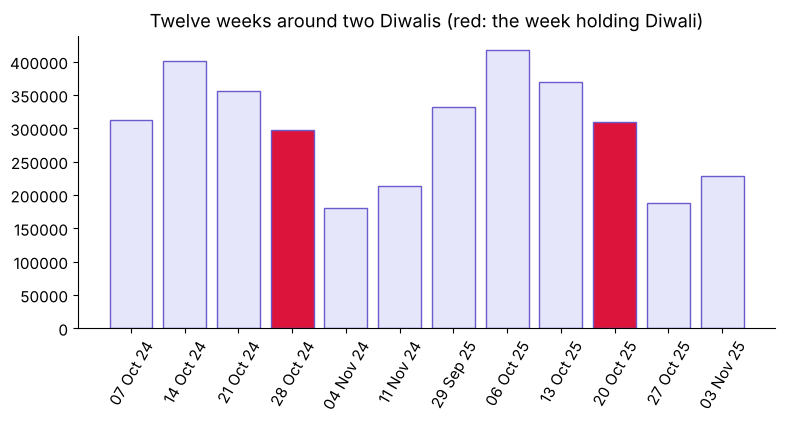

2024 busiest week: 2024-10-14 401,000 shipments
2025 busiest week: 2025-10-06 418,200 shipments
PASS both peaks sit two weeks before Diwali's week


In [2]:
diwali = pd.to_datetime(["2024-10-28", "2025-10-20"])   # the weeks holding Diwali
colours = ["crimson" if d in diwali else "lavender" for d in rows.week_start]
fig, ax = plt.subplots()
labels = rows.week_start.dt.strftime("%d %b %y")                 # each date as text, such as 14 Oct 24
ax.bar(labels, rows.shipments, color=colours, edgecolor="slateblue")
ax.tick_params(axis="x", rotation=60)
ax.set_title("Twelve weeks around two Diwalis (red: the week holding Diwali)")
plt.show()
peaks = []
for year in [2024, 2025]:
    one_year = rows[rows.week_start.dt.year == year]          # that year's six rows
    top = one_year.loc[one_year.shipments.idxmax()]           # the row with the most shipments
    print(year, "busiest week:", top.week_start.date(), f"{top.shipments:,} shipments")
    peaks.append(top.week_start)
check("both peaks sit two weeks before Diwali's week", peaks == list(pd.to_datetime(["2024-10-14", "2025-10-06"])))

**What happened.** The answer is c. The busiest week is two weeks before Diwali's week in
both years: 401,000 shipments in the week of 14 October 2024 and 418,200 in the week of 6
October 2025. Both fall in the festive sale, which runs in the third and second weeks before
Diwali's week, and parcels leave the centre with the sale so they arrive before the
festival. Diwali's own week ships less (296,900 and 308,900), and the week after falls
lowest.

## What do three rules forecast for Diwali 2025's own week?

Stand in the week of 13 October 2025 and forecast the next week, 20 October 2025, with the
rules notebook 02 built on the stall (invented). **Naive** repeats the week before. **The
seasonal naive** with a season of 52 weeks copies the week 52 weeks back, the week of 21
October 2024; the planners call it **same week last year**, and the afternoon's tournament,
a contest that scores every rule on weeks it never saw, calls it **the house bot**.
**Festival-aligned** copies the week at the same distance from last year's Diwali, which is
Diwali 2024's own week, 28 October 2024. It adds no growth here: in October 2025 the data
held no full year outside the festival to measure growth on, and the 4 percent that
chapter 6 uses is measured on weeks up to June 2026, which this forecast cannot see.

**Predict before you run.** Which rule lands closest to the 308,900 that shipped?

a) naive
b) the seasonal naive, same week last year
c) festival-aligned
d) all three land within 10,000

In [3]:
actual = s[pd.Timestamp("2025-10-20")]                    # Diwali 2025's own week
naive = s[pd.Timestamp("2025-10-13")]                     # the week before
seasonal = s[pd.Timestamp("2024-10-21")]                  # 52 weeks back: same week last year
aligned = s[pd.Timestamp("2024-10-28")]                  # Diwali 2024's own week; no growth, which October 2025 could not measure
for name, forecast in [("naive", naive), ("seasonal naive", seasonal), ("festival-aligned", aligned)]:
    print(f"{name}: forecast {forecast:,}, miss {forecast - actual:+,}")
check("festival-aligned lands closest",
      abs(aligned - actual) < min(abs(naive - actual), abs(seasonal - actual)))

naive: forecast 369,000, miss +60,100
seasonal naive: forecast 356,200, miss +47,300
festival-aligned: forecast 296,900, miss -12,000
PASS festival-aligned lands closest


**What happened.** The answer is c. Naive misses by 60,100 and the seasonal naive by
47,300, both too high; festival-aligned misses by 12,000, too low, by about the year's
growth that nobody could measure yet. A miss here is the forecast minus what shipped, so a
positive miss is too high. The week 52 weeks back looks like "the same
week", but in 2024 it was the week before Diwali, and the week before Diwali ships more than
Diwali's own week.

## Which week does a copy of last year put the peak in?

**The plausible wrong answer.** "Same week last year already knows the season, so it is the
safe rule for a festival." Copy every 2025 week from 52 weeks back with the seasonal naive
and see where its peak lands. Beside it, festival-aligned reaches back 51 weeks, because
Diwali 2025's week came 51 weeks after Diwali 2024's.

            actual  seasonal naive  festival-aligned
2025-09-29  331200            <NA>            312900
2025-10-06  418200          312900            401000
2025-10-13  369000          401000            356200
2025-10-20  308900          356200            296900
2025-10-27  188600          296900            180600
2025-11-03  227900          180600            212700


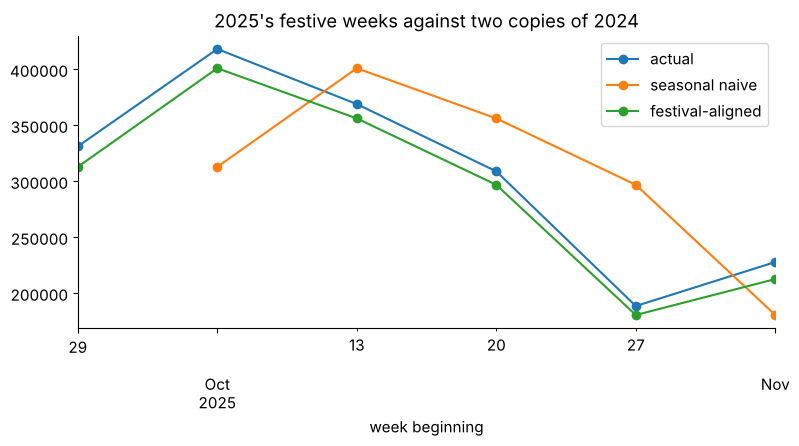

PASS the copy of last year peaks on 13 Oct 2025
PASS the actual peak is 6 Oct 2025


In [4]:
y25 = s[s.index.year == 2025]                             # the six 2025 rows
copy52, copy51 = {}, {}
for d in y25.index:
    copy52[d] = s.get(d - pd.Timedelta(weeks=52))           # blank when that week is not in the twelve rows
    copy51[d] = s[d - pd.Timedelta(weeks=51)]                # the week at the same distance from Diwali, no growth
table = pd.DataFrame({"actual": y25, "seasonal naive": pd.Series(copy52).astype("Int64"),
                      "festival-aligned": pd.Series(copy51)})
print(table.to_string())
ax = table.astype(float).plot(marker="o", title="2025's festive weeks against two copies of 2024")
ax.set_xlabel("week beginning")
plt.show()
check("the copy of last year peaks on 13 Oct 2025", table["seasonal naive"].idxmax() == pd.Timestamp("2025-10-13"))
check("the actual peak is 6 Oct 2025", y25.idxmax() == pd.Timestamp("2025-10-06"))

**Why it is wrong.** Diwali's week came one week earlier in 2025, so the copy of the same
calendar week put 2024's peak (401,000) on 13 October 2025, a week late, and left the real
peak week short. The check that catches it is the calendar: line up each year's weeks by
their distance from Diwali before copying, as notebook 02 did for the stall's days
(invented). Every festival-aligned week sits a little low, by the growth it leaves out. The
week of 29 September 2025 shows a blank in the copy, because its source, 30 September 2024,
is not one of the twelve rows.

## How far does Diwali's week move between 2025 and 2026?

Diwali 2026 falls on Sunday 8 November, so its week begins Monday 2 November 2026. Count the
weeks from Diwali 2025's week, and set them beside the 52 weeks a copy of last year steps
back. Where that puts this year's rush is chapter 7's question, so hold your answer.

In [5]:
diwali_2025, diwali_2026 = pd.Timestamp("2025-10-20"), pd.Timestamp("2026-11-02")
gap = (diwali_2026 - diwali_2025).days // 7                # weeks from one Diwali week to the next
print("weeks from Diwali 2025's week to Diwali 2026's:", gap)
print("weeks a copy of last year steps back: 52")
check("Diwali's week moves 54 weeks on, more than a year of weeks", gap == 54)

weeks from Diwali 2025's week to Diwali 2026's: 54
weeks a copy of last year steps back: 52
PASS Diwali's week moves 54 weeks on, more than a year of weeks


## Does the full series show the same shape?

The twelve rows came from 104 weeks. The ticket's `calendar` table flags each week that
holds Diwali and each sale week, so the full series can be read against both.

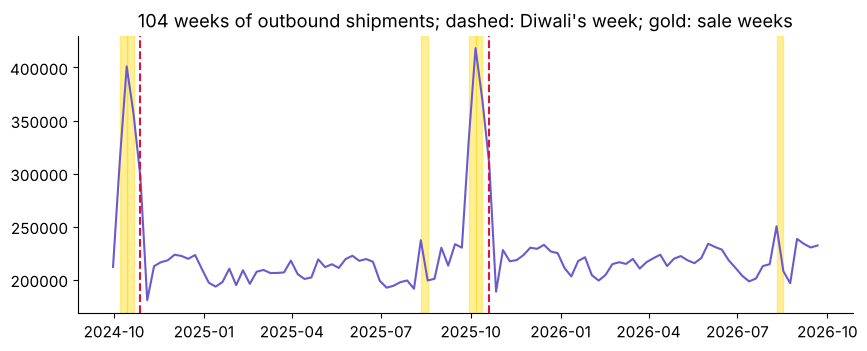

festive sale weeks: ['2024-10-07', '2024-10-14', '2025-09-29', '2025-10-06', '2026-10-12', '2026-10-19']
PASS 104 weeks
PASS the twelve rows are rows of the full series
PASS each festive sale runs three and two weeks before Diwali's week


In [6]:
weekly = pd.read_csv("../data/C2_W04_D05_weekly_shipments_STUDENT.csv", parse_dates=["week_start"])
calendar = pd.read_csv("../data/C2_W04_D05_calendar_STUDENT.csv", parse_dates=["week_start"])
sale = calendar.loc[calendar.sale_week == 1, "week_start"]          # every sale week the calendar flags
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(weekly.week_start, weekly.shipments, color="slateblue")
for d in diwali:
    ax.axvline(d, color="crimson", ls="--")
for d in sale[sale <= weekly.week_start.max()]:
    ax.axvspan(d, d + pd.Timedelta(days=7), color="gold", alpha=0.4)
ax.set_title("104 weeks of outbound shipments; dashed: Diwali's week; gold: sale weeks")
plt.show()
festive_sale = [d for d in sale if d.month in (9, 10)]               # the festive sale, without August's
expected = []
for w in calendar.loc[calendar.diwali_week == 1, "week_start"]:
    expected += [w - pd.Timedelta(weeks=3), w - pd.Timedelta(weeks=2)]
print("festive sale weeks:", [str(d.date()) for d in festive_sale])
check("104 weeks", len(weekly) == 104)
check("the twelve rows are rows of the full series",
      rows.merge(weekly, on=["week_start", "shipments"]).shape[0] == 12)
check("each festive sale runs three and two weeks before Diwali's week", sorted(expected) == sorted(festive_sale))

## What did chapter 5 answer?

- **Where is the peak?** Two weeks before Diwali's week in both years, in the sale weeks:
  401,000 and 418,200.
- **What do three rules say for 20 October 2025?** Naive 369,000, the seasonal naive (same
  week last year) 356,200, festival-aligned 296,900, 12,000 low, against 308,900 shipped.
- **Where does a copy of last year put the peak?** A week late in 2025. In 2026 Diwali's
  week comes 54 weeks after 2025's, where a copy steps back 52; chapter 7 asks what that
  does to this year's rush.
- **Does the full series agree?** Yes: two festive peaks in the sale weeks, an August sale,
  ordinary weeks a little above 210,000.

Chapter 6 asks the question one week cannot settle: how does each rule score on thirteen
weeks it never saw?